In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression

df = pd.read_csv("../data/clean.csv")

print("Размер датасета:", df.shape)
print("Пропуски:", df.isna().sum().sum())
print("Дубликаты:", df.duplicated().sum())

display(df.head())


Размер датасета: (649, 33)
Пропуски: 0
Дубликаты: 0


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [2]:
target = "G3"
X = df.drop(columns=["G3", "at_risk"], errors="ignore")
y = df[target]

num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()

print("Числовых признаков:", len(num_cols))
print("Категориальных признаков:", len(cat_cols))
print("Целевая переменная:", target)


Числовых признаков: 15
Категориальных признаков: 17
Целевая переменная: G3


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42
)
print("Обучающая выборка:", X_train.shape)
print("Тестовая выборка:", X_test.shape)


Обучающая выборка: (486, 32)
Тестовая выборка: (163, 32)


CV R² полной модели: 0.837774

ТОП-15 коэффициентов Lasso:


,weight
pipeline-1__G2,2.451755
pipeline-1__G1,0.476178
pipeline-2__absences_0.0,-0.220154
pipeline-3__school_GP,0.079354
pipeline-1__failures,-0.047579
pipeline-1__Dalc,-0.045504
pipeline-1__health,-0.033784
pipeline-1__freetime,-0.030654
pipeline-1__studytime,0.025661
pipeline-1__famrel,-0.016716



Важность признаков через удаление:


,delta_cv_r2
G2,0.145489
G1,0.005589
absences,0.002027
studytime,0.000149
Mjob,0.000138
school,0.000132
famsup,0.000003
guardian,0.000000
activities,0.000000
nursery,0.000000


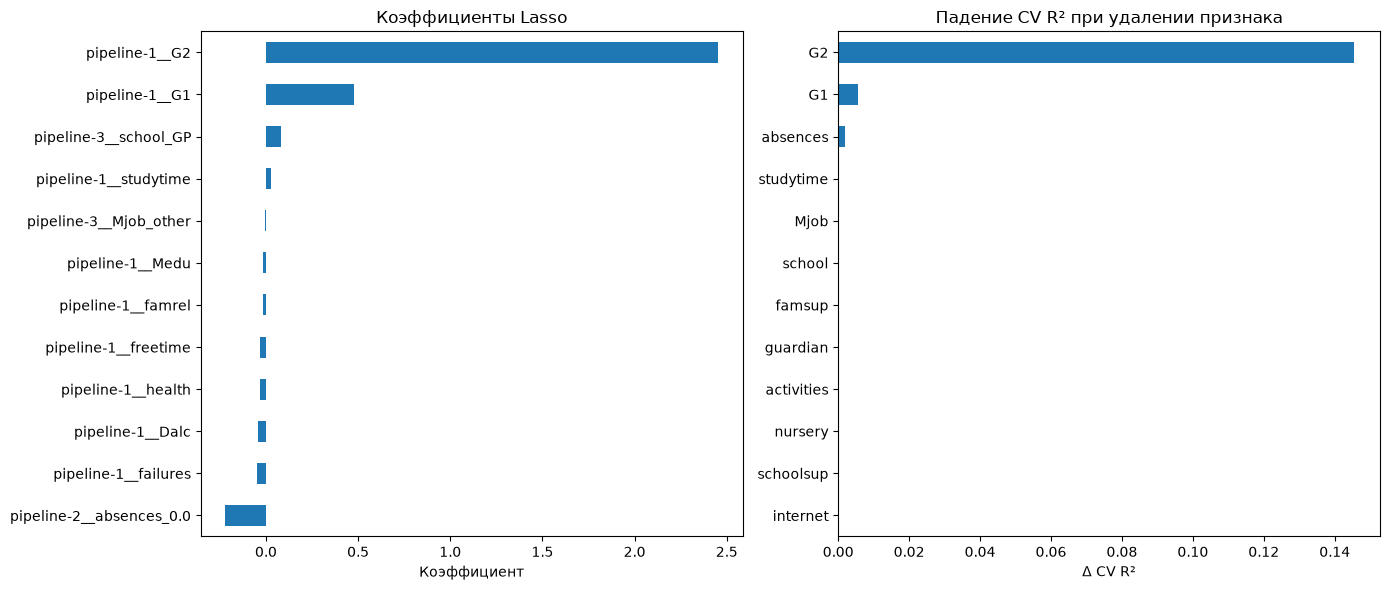


Корреляция G1 и G2: 0.8561
Важность G1: 0.005589
Важность G2: 0.145489

Асимметрия G3: -0.9913
Обычная Lasso CV R²: 0.837774
Lasso + log1p(G3) CV R²: 0.713375


In [ ]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import make_column_transformer, TransformedTargetRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import (
    StandardScaler, OneHotEncoder, KBinsDiscretizer
)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Lasso

warnings.filterwarnings(
    "ignore",
    message="Bins whose width are too small.*"
)

# 1. Данные
df = pd.read_csv("../data/clean.csv")

X = df.drop(columns=["G3", "at_risk"], errors="ignore")
y = df["G3"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

alpha = 0.05150678076168122

def make_lasso(cols):
    num = [
        c for c in cols
        if pd.api.types.is_numeric_dtype(X[c])
        and c != "absences"
    ]
    cat = [
        c for c in cols
        if not pd.api.types.is_numeric_dtype(X[c])
    ]
    transformers = []
    if num:
        transformers.append((
            make_pipeline(
                SimpleImputer(strategy="median"),
                StandardScaler()
            ),
            num
        ))
    if "absences" in cols:
        transformers.append((
            make_pipeline(
                SimpleImputer(strategy="median"),
                KBinsDiscretizer(
                    n_bins=20,
                    encode="onehot",
                    strategy="quantile"
                )
            ),
            ["absences"]
        ))
    if cat:
        transformers.append((
            make_pipeline(
                SimpleImputer(strategy="most_frequent"),
                OneHotEncoder(handle_unknown="ignore")
            ),
            cat
        ))
    prep = make_column_transformer(*transformers)
    return make_pipeline(
        prep,
        Lasso(alpha=alpha, max_iter=50000)
    )
model = make_lasso(X.columns.tolist())
base_r2 = cross_val_score(
    model, X_train, y_train,
    cv=5, scoring="r2"
).mean()
model.fit(X_train, y_train)
print("CV R² полной модели:", round(base_r2, 6))
feature_names = model[0].get_feature_names_out()
weights = pd.Series(
    model[-1].coef_,
    index=feature_names
)

weights = weights.reindex(
    weights.abs().sort_values(ascending=False).index
)
print("\nТОП-15 коэффициентов Lasso:")
display(weights.head(15).round(6).to_frame("weight"))
importance = {}
for col in X.columns:
    remaining = [c for c in X.columns if c != col]

    reduced_model = make_lasso(remaining)

    reduced_r2 = cross_val_score(
        reduced_model,
        X_train[remaining],
        y_train,
        cv=5,
        scoring="r2"
    ).mean()

    importance[col] = base_r2 - reduced_r2

importance_df = (
    pd.Series(importance, name="delta_cv_r2")
    .sort_values(ascending=False)
)

print("\nВажность признаков через удаление:")
display(importance_df.round(6).to_frame())

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

weights.head(12).sort_values().plot.barh(
    ax=axes[0],
    title="Коэффициенты Lasso"
)
axes[0].set_xlabel("Коэффициент")

importance_df.head(12).sort_values().plot.barh(
    ax=axes[1],
    title="Падение CV R² при удалении признака"
)
axes[1].set_xlabel("Δ CV R²")

plt.tight_layout()
plt.show()

corr = X_train[["G1", "G2"]].corr().iloc[0, 1]

print("\nКорреляция G1 и G2:", round(corr, 4))
print("Важность G1:", round(importance_df["G1"], 6))
print("Важность G2:", round(importance_df["G2"], 6))
print("\nАсимметрия G3:", round(y_train.skew(), 4))

log_model = TransformedTargetRegressor(
    regressor=make_lasso(X.columns.tolist()),
    func=np.log1p,
    inverse_func=np.expm1
)

log_r2 = cross_val_score(
    log_model, X_train, y_train,
    cv=5, scoring="r2"
).mean()

print("Обычная Lasso CV R²:", round(base_r2, 6))
print("Lasso + log1p(G3) CV R²:", round(log_r2, 6))
